# AdaBoost from Scratch

This is an **optional** notebook. Earlier we combined models that were trained independently and then pooled (voting, averaging, stacking). *Boosting* takes a different route: it trains weak learners one after another, and each new learner concentrates on the points the previous ones got wrong. AdaBoost ("adaptive boosting") is the classic example. Here you read through a compact, from-scratch implementation and watch the error rate fall as more weak learners are added.

## Learning Objectives

At the end of this notebook, you should be able to:

- Trace how AdaBoost trains weak learners in sequence, each focusing on the previous round's mistakes.
- Compute the AdaBoost update: scoring each learner and reweighting the misclassified points.
- Apply a from-scratch AdaBoost to a benchmark dataset and measure training and test error.
- Visualise how the error rate falls as the number of boosting rounds grows.

The following code is friendly borrowed from [Jaime Pastor](https://github.com/jaimeps/adaboost-implementation/blob/master/adaboost.py). 

Go through the code and try to understand what each function is doing. Don't forget to write some comments or add a docstring to the functions. 

## How AdaBoost Works

A single decision stump (a tree of depth 1) is a *weak learner*: on a hard problem it is only a little better than guessing. AdaBoost turns a sequence of these weak learners into a strong one. It keeps a weight on every training point. Each round it trains a stump on the weighted data, gives that stump a say (`alpha`) based on how accurate it was, then raises the weights on the points the stump misclassified so the next stump pays them more attention. The final prediction is a weighted vote of all the stumps.

This is the opposite trade-off to bagging (used by a random forest), where many trees are trained independently and in parallel to reduce variance. Boosting trains its learners in sequence to reduce bias, so it can turn shallow, high-bias stumps into an accurate model.




```mermaid
flowchart TD
    A["Start: equal weights on every training point"] --> B["Train a weak learner (a decision stump) on the weighted data"]
    B --> C["Measure its weighted error and compute its say (alpha)"]
    C --> D["Raise the weights on the points it got wrong"]
    D --> E{"Done M rounds?"}
    E -->|"No"| B
    E -->|"Yes"| F["Final model: weighted vote of all the weak learners"]
```


## Setup

Import the libraries. `make_hastie_10_2` generates a binary classification problem that is deliberately hard for a single stump, which makes the effect of boosting easy to see.

In [1]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import (
    make_hastie_10_2,
)  # make_hastie_10_2 generates a data set for binary classification
import matplotlib.pyplot as plt

## Helper Functions

Two small helpers measure the error rate (the fraction of misclassified points) and print it, and a third trains and scores any single classifier as a baseline to compare against.

In [2]:
""" HELPER FUNCTION: GET ERROR RATE ========================================="""


def get_error_rate(pred, Y):
    """Share of predictions that differ from the true labels (0 = perfect)."""
    return sum(pred != Y) / float(len(Y))


""" HELPER FUNCTION: PRINT ERROR RATE ======================================="""


def print_error_rate(err):
    """Print a (train error, test error) pair with four decimals."""
    print("Error rate: Training: %.4f - Test: %.4f" % err)


""" HELPER FUNCTION: GENERIC CLASSIFIER ====================================="""


def generic_clf(Y_train, X_train, Y_test, X_test, clf):
    """Fit any classifier once and return its (train error, test error).

    Used for the baseline: a single decision stump without boosting.
    """
    clf.fit(X_train, Y_train)
    pred_train = clf.predict(X_train)
    pred_test = clf.predict(X_test)
    return get_error_rate(pred_train, Y_train), get_error_rate(pred_test, Y_test)

## The AdaBoost Algorithm

This is the heart of the notebook. Read it against the loop diagram above: `w` holds the per-point weights, `err_m` is the weighted error of the current stump, `alpha_m` is its say in the final vote, and the `w = w * exp(...)` line is where the misclassified points have their weights raised. The running `pred_train` and `pred_test` accumulate the weighted votes, and `np.sign` turns the accumulated score into a class label.

The task above asks us to add comments and docstrings: every `#` line in the function below is our own plain-word note.

In [3]:
""" ADABOOST IMPLEMENTATION ================================================="""


def adaboost_clf(Y_train, X_train, Y_test, X_test, M, clf):
    """Run M rounds of AdaBoost with the weak learner clf.

    Labels must be -1 / +1. Each round fits clf on weighted data, gives it
    a say (alpha) and raises the weights of the points it got wrong.
    Returns the (train error, test error) of the weighted vote.
    """
    n_train, n_test = len(X_train), len(X_test)
    # Start with equal weights: every training point counts 1 / n
    w = np.ones(n_train) / n_train
    # Running sums of the weighted votes, one number per point
    pred_train, pred_test = [np.zeros(n_train), np.zeros(n_test)]

    for i in range(M):
        # Fit the weak learner on the data, weighted by w
        clf.fit(X_train, Y_train, sample_weight=w)
        pred_train_i = clf.predict(X_train)
        pred_test_i = clf.predict(X_test)
        # miss = 1 where this learner is wrong, 0 where it is right
        miss = [int(x) for x in (pred_train_i != Y_train)]
        # miss2 = +1 for wrong, -1 for right (the sign of the weight change)
        miss2 = [x if x == 1 else -1 for x in miss]
        # Weighted error: the share of weight sitting on the wrong points
        err_m = np.dot(w, miss) / sum(w)
        # Say of this learner: big when err_m is small, 0 when err_m = 0.5
        alpha_m = 0.5 * np.log((1 - err_m) / float(err_m))
        # Wrong points: weight x e^alpha (up). Right points: x e^-alpha (down)
        w = np.multiply(w, np.exp([float(x) * alpha_m for x in miss2]))
        # Add this learner's vote (+1 / -1 times alpha) to the running sums
        pred_train = [
            sum(x) for x in zip(pred_train, [x * alpha_m for x in pred_train_i])
        ]
        pred_test = [sum(x) for x in zip(pred_test, [x * alpha_m for x in pred_test_i])]

    # Final label = the sign of the weighted vote (+1 or -1)
    pred_train, pred_test = np.sign(pred_train), np.sign(pred_test)
    # Return how often the final vote is wrong on train and on test
    return get_error_rate(pred_train, Y_train), get_error_rate(pred_test, Y_test)

## Plotting the Error Rate

A small helper to plot the training and test error against the number of boosting rounds, with a dashed line marking the single-stump baseline.

In [4]:
""" PLOT FUNCTION ==========================================================="""


def plot_error_rate(er_train, er_test, rounds=None):
    """Plot training and test error against the number of boosting rounds.

    rounds: the x value of each point (here 0, 10, ..., 400; 0 = the single
    stump). The dashed red line repeats the single-stump test error.
    """
    df_error = pd.DataFrame({"Training": er_train, "Test": er_test})
    if rounds is not None:
        # put the real number of rounds on the x axis
        df_error.index = rounds
    plot1 = df_error.plot(
        linewidth=3, figsize=(8, 6), color=["lightblue", "darkblue"], grid=True
    )
    plot1.set_xlabel("Number of iterations (boosting rounds)", fontsize=12)
    plot1.set_ylabel("Error rate", fontsize=12)
    plot1.set_title("Error rate vs number of iterations", fontsize=16)
    plt.axhline(y=er_test[0], linewidth=1, color="red", ls="dashed")

## Running the Experiment

We generate the Hastie dataset, fit a single decision stump as the baseline, then run AdaBoost for a growing number of rounds (10, 20, ..., 400) and record the error each time. Plotting these shows how the ensemble improves as more weak learners are added.

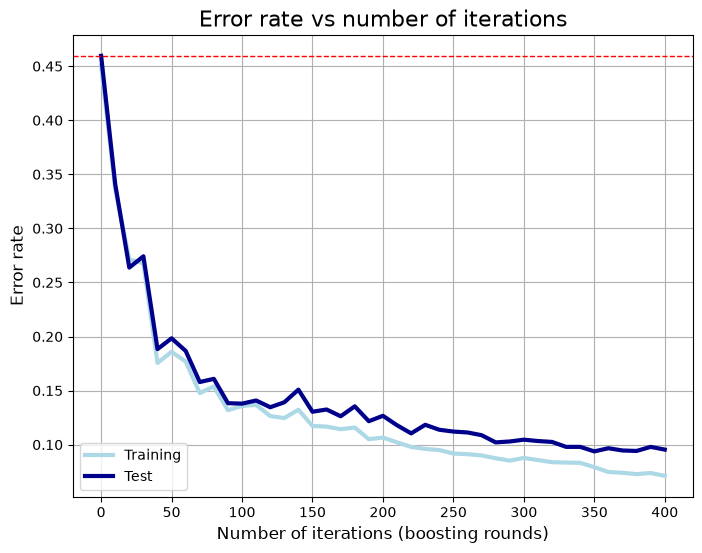

In [5]:
""" MAIN SCRIPT ============================================================="""
if __name__ == "__main__":
    # Read data
    # random_state makes the run repeatable (added by us)
    x, y = make_hastie_10_2(random_state=42)
    df = pd.DataFrame(x)
    df["Y"] = y

    # Split into training and test set
    train, test = train_test_split(df, test_size=0.2, random_state=42)
    X_train, Y_train = train.iloc[:, :-1], train.iloc[:, -1]
    X_test, Y_test = test.iloc[:, :-1], test.iloc[:, -1]

    # Fit a simple decision tree first
    clf_tree = DecisionTreeClassifier(max_depth=1, random_state=1)
    er_tree = generic_clf(Y_train, X_train, Y_test, X_test, clf_tree)

    # Fit Adaboost classifier using a decision tree as base estimator
    # Test with different number of iterations
    er_train, er_test = [er_tree[0]], [er_tree[1]]
    x_range = range(10, 410, 10)
    for i in x_range:
        er_i = adaboost_clf(Y_train, X_train, Y_test, X_test, i, clf_tree)
        er_train.append(er_i[0])
        er_test.append(er_i[1])

    # Compare error rate vs number of iterations
    plot_error_rate(er_train, er_test, rounds=[0] + list(x_range))

In [6]:
# The numbers behind the curve
print_error_rate(er_tree)
for rounds in [10, 50, 100, 200, 400]:
    k = list(x_range).index(rounds) + 1
    print(f"{rounds:>3} rounds -> train {er_train[k]:.4f}, test {er_test[k]:.4f}")

Error rate: Training: 0.4506 - Test: 0.4596
 10 rounds -> train 0.3364, test 0.3408
 50 rounds -> train 0.1858, test 0.1983
100 rounds -> train 0.1357, test 0.1379
200 rounds -> train 0.1066, test 0.1267
400 rounds -> train 0.0711, test 0.0954


### Cross-check with scikit-learn

Our hand-made loop should behave like the ready-made `AdaBoostClassifier`. We train it with the same stump and 400 rounds.

In [7]:
from sklearn.ensemble import AdaBoostClassifier

sk_ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=1),
    n_estimators=400, random_state=42,
)
er_sk = generic_clf(Y_train, X_train, Y_test, X_test, sk_ada)
print_error_rate(er_sk)

Error rate: Training: 0.0711 - Test: 0.0954


**Same result, both ways.** After 400 rounds our hand-written loop and scikit-learn's `AdaBoostClassifier` give exactly the same error rates: 0.0711 on the training rows and 0.0954 on the test rows. scikit-learn writes the update slightly differently (it drops the factor 0.5 in alpha and only raises the weights of wrong points before normalising), but the final votes come out the same, so the predictions match.

### Reading the Result

The single stump alone gets 0.4596 of the test points wrong: barely better than a coin flip on this hard problem. As AdaBoost adds rounds, the error falls steadily:

| Rounds | Training error | Test error |
|---|---|---|
| 1 stump (no boosting) | 0.4506 | 0.4596 |
| 10 | 0.3364 | 0.3408 |
| 50 | 0.1858 | 0.1983 |
| 100 | 0.1357 | 0.1379 |
| 200 | 0.1066 | 0.1267 |
| 400 | 0.0711 | 0.0954 |

Training and test curves fall together and stay close, so AdaBoost is learning a real pattern, not just memorising the training points. Towards 400 rounds the gap widens a little (0.071 vs 0.095): more rounds would bring smaller gains and slowly more overfitting.

We fixed `random_state=42` in `make_hastie_10_2`, so these numbers repeat exactly on every run.

## Summary

In this notebook you:

- Traced a from-scratch AdaBoost built on decision stumps.
- Followed the weight update that reweights misclassified points and scores each weak learner.
- Applied the algorithm to the Hastie benchmark and measured training and test error.
- Visualised the error rate falling from 0.46 for a single stump to 0.095 after 400 rounds (test error).
- Checked our loop against scikit-learn's `AdaBoostClassifier`: identical error rates.

## References & Further Reading

- [**Scikit-learn: AdaBoostClassifier**](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html): The ready-made AdaBoost you would reach for in practice.
- [**Scikit-learn: Ensemble Methods**](https://scikit-learn.org/stable/modules/ensemble.html): User guide covering boosting alongside bagging, voting, and stacking.
- [**Multi-class AdaBoosted Decision Trees**](https://scikit-learn.org/stable/auto_examples/ensemble/plot_adaboost_multiclass.html): A worked scikit-learn example of AdaBoost in action.
- [**AdaBoost implementation by Jaime Pastor**](https://github.com/jaimeps/adaboost-implementation): The original source this notebook adapts.